<a href="https://colab.research.google.com/github/igupansini/utfpr-AI/blob/main/POSIA05-Redes_Neurais_Artificiais/Tarefa_Autoencoder_FashionMNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Exercício Autoencoder - Fashion MNIST

Aplicação da mesma técnica do exemplo prático com o dataset MNIST ao dataset Fashion MNIST, carregado pela própria API do Keras (from keras.datasets import fashion_mnist).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras.datasets import fashion_mnist
from keras.layers import Dense, Input
from keras.models import Sequential
from sklearn import metrics

Carregamento e Tratamento dos Dados

Os valores dos pixels (0 a 255) são normalizados para o intervalo [0, 1] e cada imagem de 28x28 é transformada em um vetor de 784 pixels, que é o formato de entrada das camadas Dense. O ruído gaussiano usa o mesmo fator do exemplo do MNIST (0.1) e é aplicado somente nas imagens de teste, já que o autoencoder é treinado apenas com as imagens originais.

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print('Amostras de treinamento:', x_train.shape)
print('Amostras de teste:', x_test.shape)

classes = ['Camiseta/Top', 'Calça', 'Pulôver', 'Vestido', 'Casaco', 'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota']

x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

x_train = x_train.reshape((len(x_train), np.prod(x_train.shape[1:])))
x_test = x_test.reshape((len(x_test), np.prod(x_test.shape[1:])))

factor = 0.1
x_test_noisy = x_test + factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)

print('Treinamento após a transformação em vetores:', x_train.shape)
print('Teste após a transformação em vetores:', x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Amostras de treinamento: (60000, 28, 28)
Amostras de teste: (10000, 28, 28)
Treinamento após a transformação em vetores: (60000, 784)
Teste após a transformação em vetores: (10000, 784)


Visualização de Algumas Imagens de Treinamento

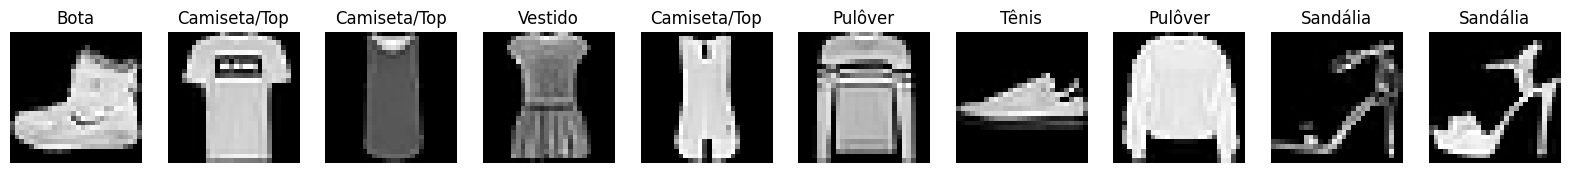

In [3]:
n = 10
plt.figure(figsize=(20, 3))
for i in range(n):
    ax = plt.subplot(1, n, i + 1)
    plt.imshow(x_train[i].reshape(28, 28), cmap='gray')
    plt.title(classes[y_train[i]])
    ax.axis('off')
plt.show()

Construção do Modelo Autoencoder

Mesma arquitetura do exemplo do MNIST. O codificador reduz os 784 pixels para uma representação de 60 neurônios (400 → 200 → 60) e o decodificador reconstrói a imagem a partir dela (200 → 400 → 784). A camada de saída usa a função sigmoide, que mantém os pixels reconstruídos no intervalo [0, 1], e a perda é a entropia cruzada binária com o otimizador Adam.

In [4]:
n_latent = 60

model = Sequential()
model.add(Input(shape=(x_train.shape[1],)))
model.add(Dense(units=400, activation='relu'))
model.add(Dense(units=200, activation='relu'))
model.add(Dense(units=n_latent, activation='relu')) # Representação codificada
model.add(Dense(units=200, activation='relu'))
model.add(Dense(units=400, activation='relu'))
model.add(Dense(units=x_train.shape[1], activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 400)            │       314,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 200)            │        80,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 60)             │        12,060 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 200)            │        12,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 400)            │        80,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 784)            │       314,384 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 813,244 (3.10 MB)

 Trainable params: 813,244 (3.10 MB)

 Non-trainable params: 0 (0.00 B)

Treinamento com os Dados Originais

A entrada e a saída desejada são a própria imagem, por isso o fit recebe x_train duas vezes. As imagens de teste sem ruído são usadas na validação. São 30 épocas com batch de 256 amostras, como no exemplo do MNIST.

In [5]:
historico = model.fit(x_train, x_train, epochs=30, batch_size=256, shuffle=True, validation_data=(x_test, x_test))

Epoch 1/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - loss: 0.3488 - val_loss: 0.3075
Epoch 2/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2987 - val_loss: 0.2952
Epoch 3/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.2895 - val_loss: 0.2887
Epoch 4/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2848 - val_loss: 0.2850
Epoch 5/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2812 - val_loss: 0.2819
Epoch 6/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2789 - val_loss: 0.2807
Epoch 7/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2768 - val_loss: 0.2788
Epoch 8/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2752 - val_loss: 0.2771
Epoch 9/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2740 - val_loss: 0.2756
Epoch 10/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2730 - val_loss: 0.2745
Epoch 11/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.2720 - val_loss: 0.2740
Epoch 12/30
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/ste

Avaliação do Erro no Processo de Treinamento

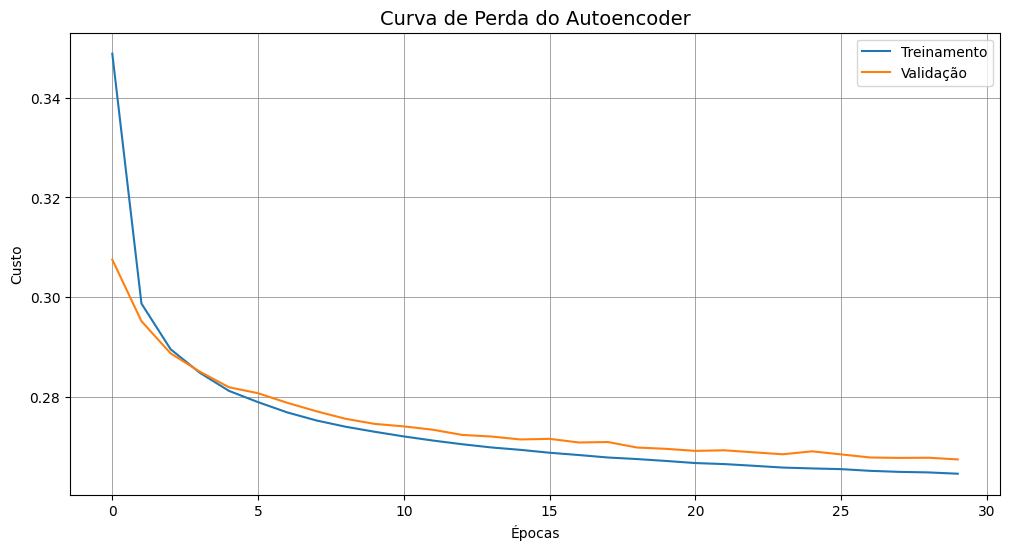

In [6]:
plt.figure(figsize=(12, 6))
plt.plot(historico.history['loss'], label='Treinamento')
plt.plot(historico.history['val_loss'], label='Validação')
plt.title('Curva de Perda do Autoencoder', fontsize=14)
plt.xlabel('Épocas')
plt.ylabel('Custo')
plt.legend()
plt.grid(which='major', linestyle='-', linewidth='0.5', color='gray')
plt.show()

Comparação entre as Imagens Originais e as Reconstruídas - sem Ruído

Linha de cima: imagens de teste originais. Linha de baixo: as mesmas imagens reconstruídas pelo autoencoder.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


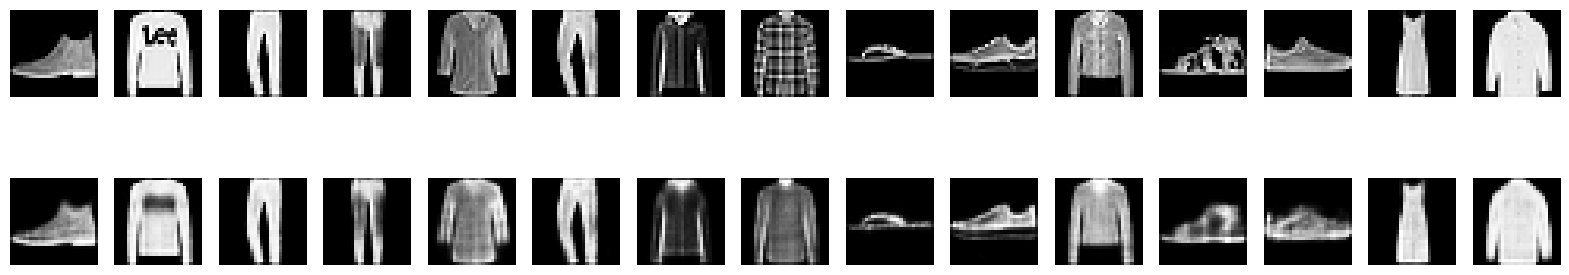

In [7]:
def comparar(entrada, saida):
    n = 15
    plt.figure(figsize=(20, 4))
    for i in range(n):
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(entrada[i].reshape(28, 28), cmap='gray')
        ax.axis('off')

        ax = plt.subplot(2, n, i + 1 + n)
        plt.imshow(saida[i].reshape(28, 28), cmap='gray')
        ax.axis('off')
    plt.show()


reconstruidas = model.predict(x_test)
comparar(x_test, reconstruidas)

Validação com Dados com Ruído Usando o Mesmo Modelo Treinado

O autoencoder não recebeu nenhuma imagem com ruído no treinamento. Como ele aprendeu a reconstruir as peças a partir da representação codificada de 60 neurônios, que não tem espaço para guardar um ruído aleatório, a tendência é que o ruído seja descartado na reconstrução.

Linha de cima: imagens de teste com ruído. Linha de baixo: as mesmas imagens recuperadas pelo autoencoder.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


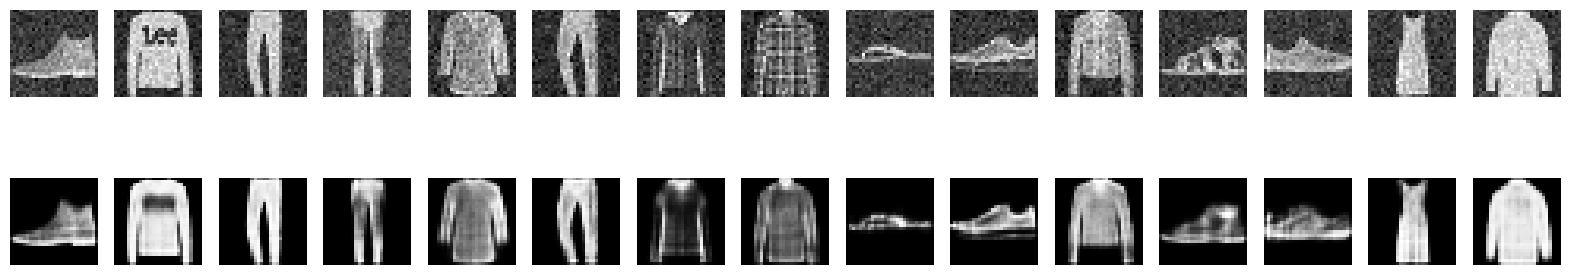

In [8]:
recuperadas = model.predict(x_test_noisy)
comparar(x_test_noisy, recuperadas)

Modelo de Classificação para as Amostras Originais, com Ruído e Recuperadas do Ruído

Mesma rede MLP classificadora do exemplo do MNIST: duas camadas ocultas com ReLU (400 e 100 neurônios) e uma camada de saída softmax com um neurônio para cada uma das 10 categorias. Ela é treinada somente com as imagens originais, por 40 épocas com batch de 256 amostras, e depois avaliada com os três conjuntos de teste.

In [9]:
num_labels = len(np.unique(y_train))

model2 = Sequential()
model2.add(Input(shape=(x_train.shape[1],)))
model2.add(Dense(units=400, activation='relu'))
model2.add(Dense(units=100, activation='relu'))
model2.add(Dense(units=num_labels, activation='softmax'))

model2.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

In [10]:
model2.fit(x_train, y_train, epochs=40, batch_size=256)

Epoch 1/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8131 - loss: 0.5355
Epoch 2/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8647 - loss: 0.3777
Epoch 3/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8769 - loss: 0.3370
Epoch 4/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8853 - loss: 0.3122
Epoch 5/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8932 - loss: 0.2909
Epoch 6/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8990 - loss: 0.2734
Epoch 7/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9046 - loss: 0.2594
Epoch 8/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9080 - loss: 0.2491
Epoch 9/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9112 - loss: 0.2387
Epoch 10/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9146 - loss: 0.2283
Epoch 11/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9196 - loss: 0.2180
Epoch 12/40
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

In [11]:
amostras = {'Originais': x_test, 'Com ruído': x_test_noisy, 'Recuperadas do ruído': recuperadas}

resultados = []
previsoes = {}

for nome in amostras:
    y_pred = np.argmax(model2.predict(amostras[nome]), axis=1) # Converte as probabilidades da softmax na classe prevista
    previsoes[nome] = y_pred
    resultados.append({'Amostras de Teste': nome,
                       'Acurácia (%)': metrics.accuracy_score(y_test, y_pred) * 100,
                       'Acertos': (y_pred == y_test).sum()})

tabela = pd.DataFrame(resultados)
tabela

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Amostras de Teste,Acurácia (%),Acertos
0,Originais,89.70,8970
1,Com ruído,87.48,8748
2,Recuperadas do ruído,86.99,8699


Métricas com o sklearn

Relatório de classificação e matriz de confusão de cada um dos três conjuntos de teste.

Relatório de classificação - Amostras Originais
              precision    recall  f1-score   support

Camiseta/Top       0.84      0.87      0.85      1000
       Calça       0.99      0.98      0.98      1000
     Pulôver       0.82      0.81      0.81      1000
     Vestido       0.90      0.91      0.90      1000
      Casaco       0.80      0.83      0.82      1000
    Sandália       0.98      0.98      0.98      1000
      Camisa       0.74      0.69      0.72      1000
       Tênis       0.95      0.98      0.96      1000
       Bolsa       0.98      0.97      0.97      1000
        Bota       0.98      0.95      0.96      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



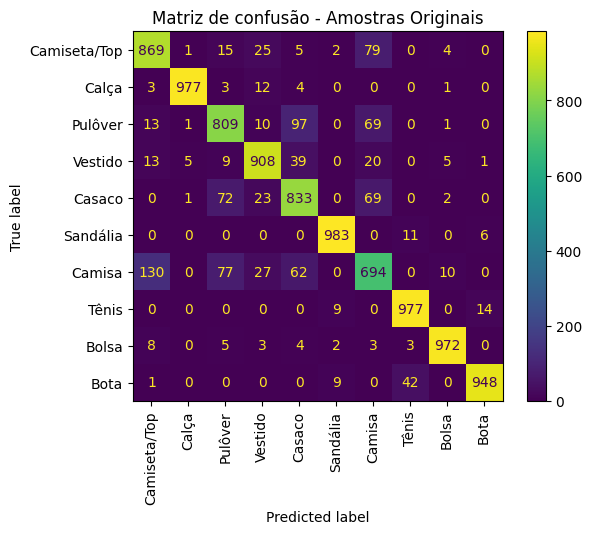

Relatório de classificação - Amostras Com ruído
              precision    recall  f1-score   support

Camiseta/Top       0.81      0.85      0.83      1000
       Calça       0.99      0.97      0.98      1000
     Pulôver       0.79      0.77      0.78      1000
     Vestido       0.88      0.88      0.88      1000
      Casaco       0.77      0.80      0.78      1000
    Sandália       0.94      0.98      0.96      1000
      Camisa       0.70      0.67      0.68      1000
       Tênis       0.92      0.94      0.93      1000
       Bolsa       0.97      0.97      0.97      1000
        Bota       0.98      0.92      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



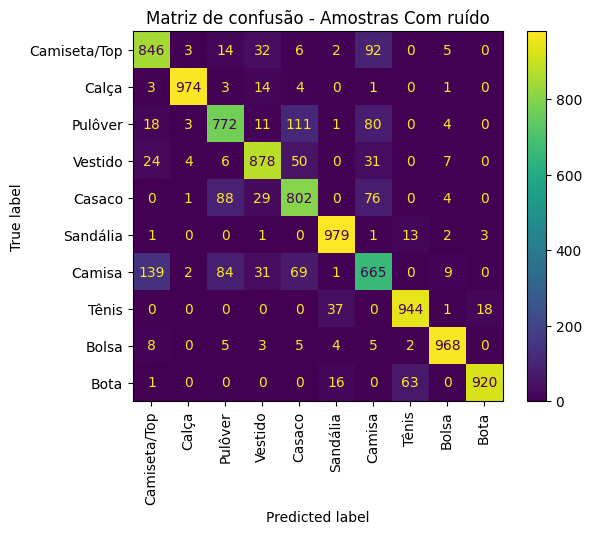

Relatório de classificação - Amostras Recuperadas do ruído
              precision    recall  f1-score   support

Camiseta/Top       0.81      0.83      0.82      1000
       Calça       0.99      0.96      0.97      1000
     Pulôver       0.79      0.78      0.78      1000
     Vestido       0.86      0.89      0.87      1000
      Casaco       0.78      0.78      0.78      1000
    Sandália       0.96      0.95      0.96      1000
      Camisa       0.67      0.65      0.66      1000
       Tênis       0.92      0.94      0.93      1000
       Bolsa       0.97      0.97      0.97      1000
        Bota       0.95      0.94      0.95      1000

    accuracy                           0.87     10000
   macro avg       0.87      0.87      0.87     10000
weighted avg       0.87      0.87      0.87     10000



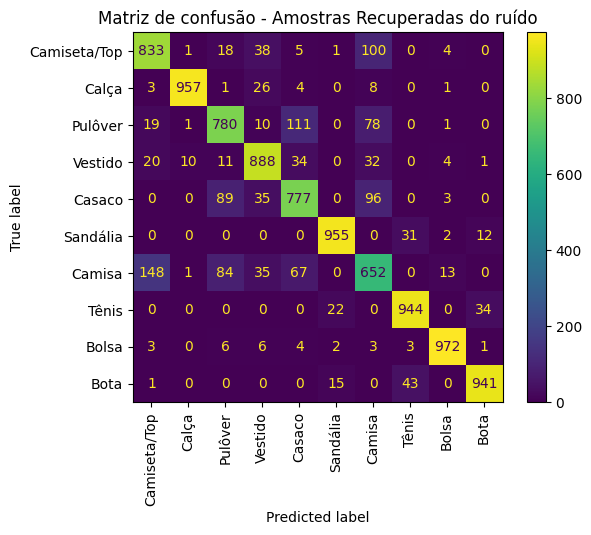

In [12]:
for nome in previsoes:
    print('Relatório de classificação - Amostras', nome)
    print(metrics.classification_report(y_test, previsoes[nome], target_names=classes))

    matriz = metrics.confusion_matrix(y_test, previsoes[nome])
    cm_display = metrics.ConfusionMatrixDisplay(confusion_matrix=matriz, display_labels=classes)
    cm_display.plot(xticks_rotation='vertical')
    plt.title('Matriz de confusão - Amostras ' + nome)
    plt.show()